In [2]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.colors import LogNorm, Normalize
import matplotlib.colors as colors
import proplot as plot
import rioxarray
import xarray as xr
import pandas as pd
import numpy as np
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import warnings
import geopandas as gpd
plot.rc['cmap.discrete'] = False
import os
warnings.filterwarnings("ignore")

ERROR 1: PROJ: proj_create_from_database: Open of /home/alessandrom/anaconda3/envs/bias_correction_conda/share/proj failed
/home/alessandrom/anaconda3/envs/bias_correction_conda/lib/python3.10/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.31.0 or higher is recommended. You are running version 2.16.0
  warnings.warn(


In [5]:
shapefile_path = '../world_map/ne_50m_admin_0_countries.shp'
country ='tanzania'

In [3]:
geometries = gpd.read_file(shapefile_path).loc[:,['ADMIN','geometry']].set_index('ADMIN')
if country == 'tanzania':
    geometries_country = geometries.loc['United Republic of Tanzania']
else:
    geometries_country = geometries.loc[f'{country.capitalize()}']

In [4]:
in_path   = f'../data/downscaled_data/{country}/'

output_path =f'../data/figures/{country}/' 
output_dir = os.path.dirname(output_path)
os.makedirs(output_dir, exist_ok=True)

month= 1
months_names = ['January','February','March','April','May','June','July',
                'August','September','October','November','December']

In [5]:
def plotting(gdf, country_rivers, country_lakes_level, units, ticks, norm):
    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(10,8), subplot_kw={'projection': ccrs.PlateCarree()})
    

    
    gdf.plot(column=f'mean_river_discharge', ax=axs, cmap = 'YlGnBu', legend = False, norm = norm, 
                               edgecolor = 'k', linewidth = 0.5)
    axs.coastlines(linewidth=0.5)
    axs.set_title(months_names[month-1],fontsize=13)
    gl = axs.gridlines(crs=ccrs.PlateCarree(),draw_labels=True,
                      linewidth=0.5, color='black', alpha=0.5, linestyle='--')
    gl.top_labels=False   
    gl.right_labels=False
    country_rivers[country_rivers.ORD_FLOW<7].plot(ax = axs, color = 'orange', linewidth= 3/country_rivers[country_rivers.ORD_FLOW<7].ORD_FLOW)
    country_lakes_level.plot(ax = axs, facecolor = 'green', zorder = 10)
    
    #ax_cbar = fig.add_axes([0.2, 0.1, 0.6, 0.03]) #tuple (left, bottom, width, height)
    cbar=plt.cm.ScalarMappable(norm=norm, cmap='YlGnBu')
    axCbar=fig.colorbar(cbar, orientation='vertical',shrink=0.7)
    axCbar.set_ticks(ticks)
    axCbar.set_label(units,size=13)
    axCbar.set_ticklabels(ticks)
    plt.suptitle('River Discharge',fontsize=17)
    plt.subplots_adjust(
                     bottom=0.1,
                     right=0.85,
                     top=0.9,
                     left=0.1,
                    wspace=0.2, #0.2
                    hspace=0.2 #0.1
                   )
    
    return fig

In [6]:
## Load rivers geometry

rivers = gpd.read_file('../hydrobasins/HydroRIVERS_v10_af_shp/HydroRIVERS_v10_af.shp')
country_rivers = gpd.clip(rivers, geometries_country.geometry)

### L5 basins

In [6]:
shp_basins_l5 = gpd.read_file('../hydrobasins/hybas_lake_af_lev05_v1c.shp')
lakes_l5 = shp_basins_l5[shp_basins_l5.LAKE == 1].geometry # Saving lakes as mask for plotting
shp_basins_l5 = shp_basins_l5[shp_basins_l5.LAKE == 0] # Exclude lakes from basins
country_l5_basins = gpd.clip(shp_basins_l5, geometries_country.geometry) # Clip basins over country. 
country_lakes_l5 = gpd.clip(lakes_l5, geometries_country.geometry)

In [9]:
gdf = gpd.read_file(in_path + f'river_discharge_l5_{country}_m{month}.geojson')

In [8]:
#Annual file for annual plot
#files_list =[]
#for month in range(1,13):
#    file = gpd.read_file(in_path + f'river_discharge_l5_tanzania_m{month}.geojson').rename(columns={'mean_river_discharge':f'river_discharge_m{month}'})
#    file[f'river_discharge_m{month}'] = file[f'river_discharge_m{month}'].fillna(1)
#    files_list.append(file)
#gdf = files_list[0].copy().drop(columns=f'river_discharge_m1')
#monthly_discharge_series = [files_list[i][f'river_discharge_m{i+1}'] for i in range(12)]
#gdf['mean_river_discharge'] = pd.concat(monthly_discharge_series, axis=1).mean(axis=1)

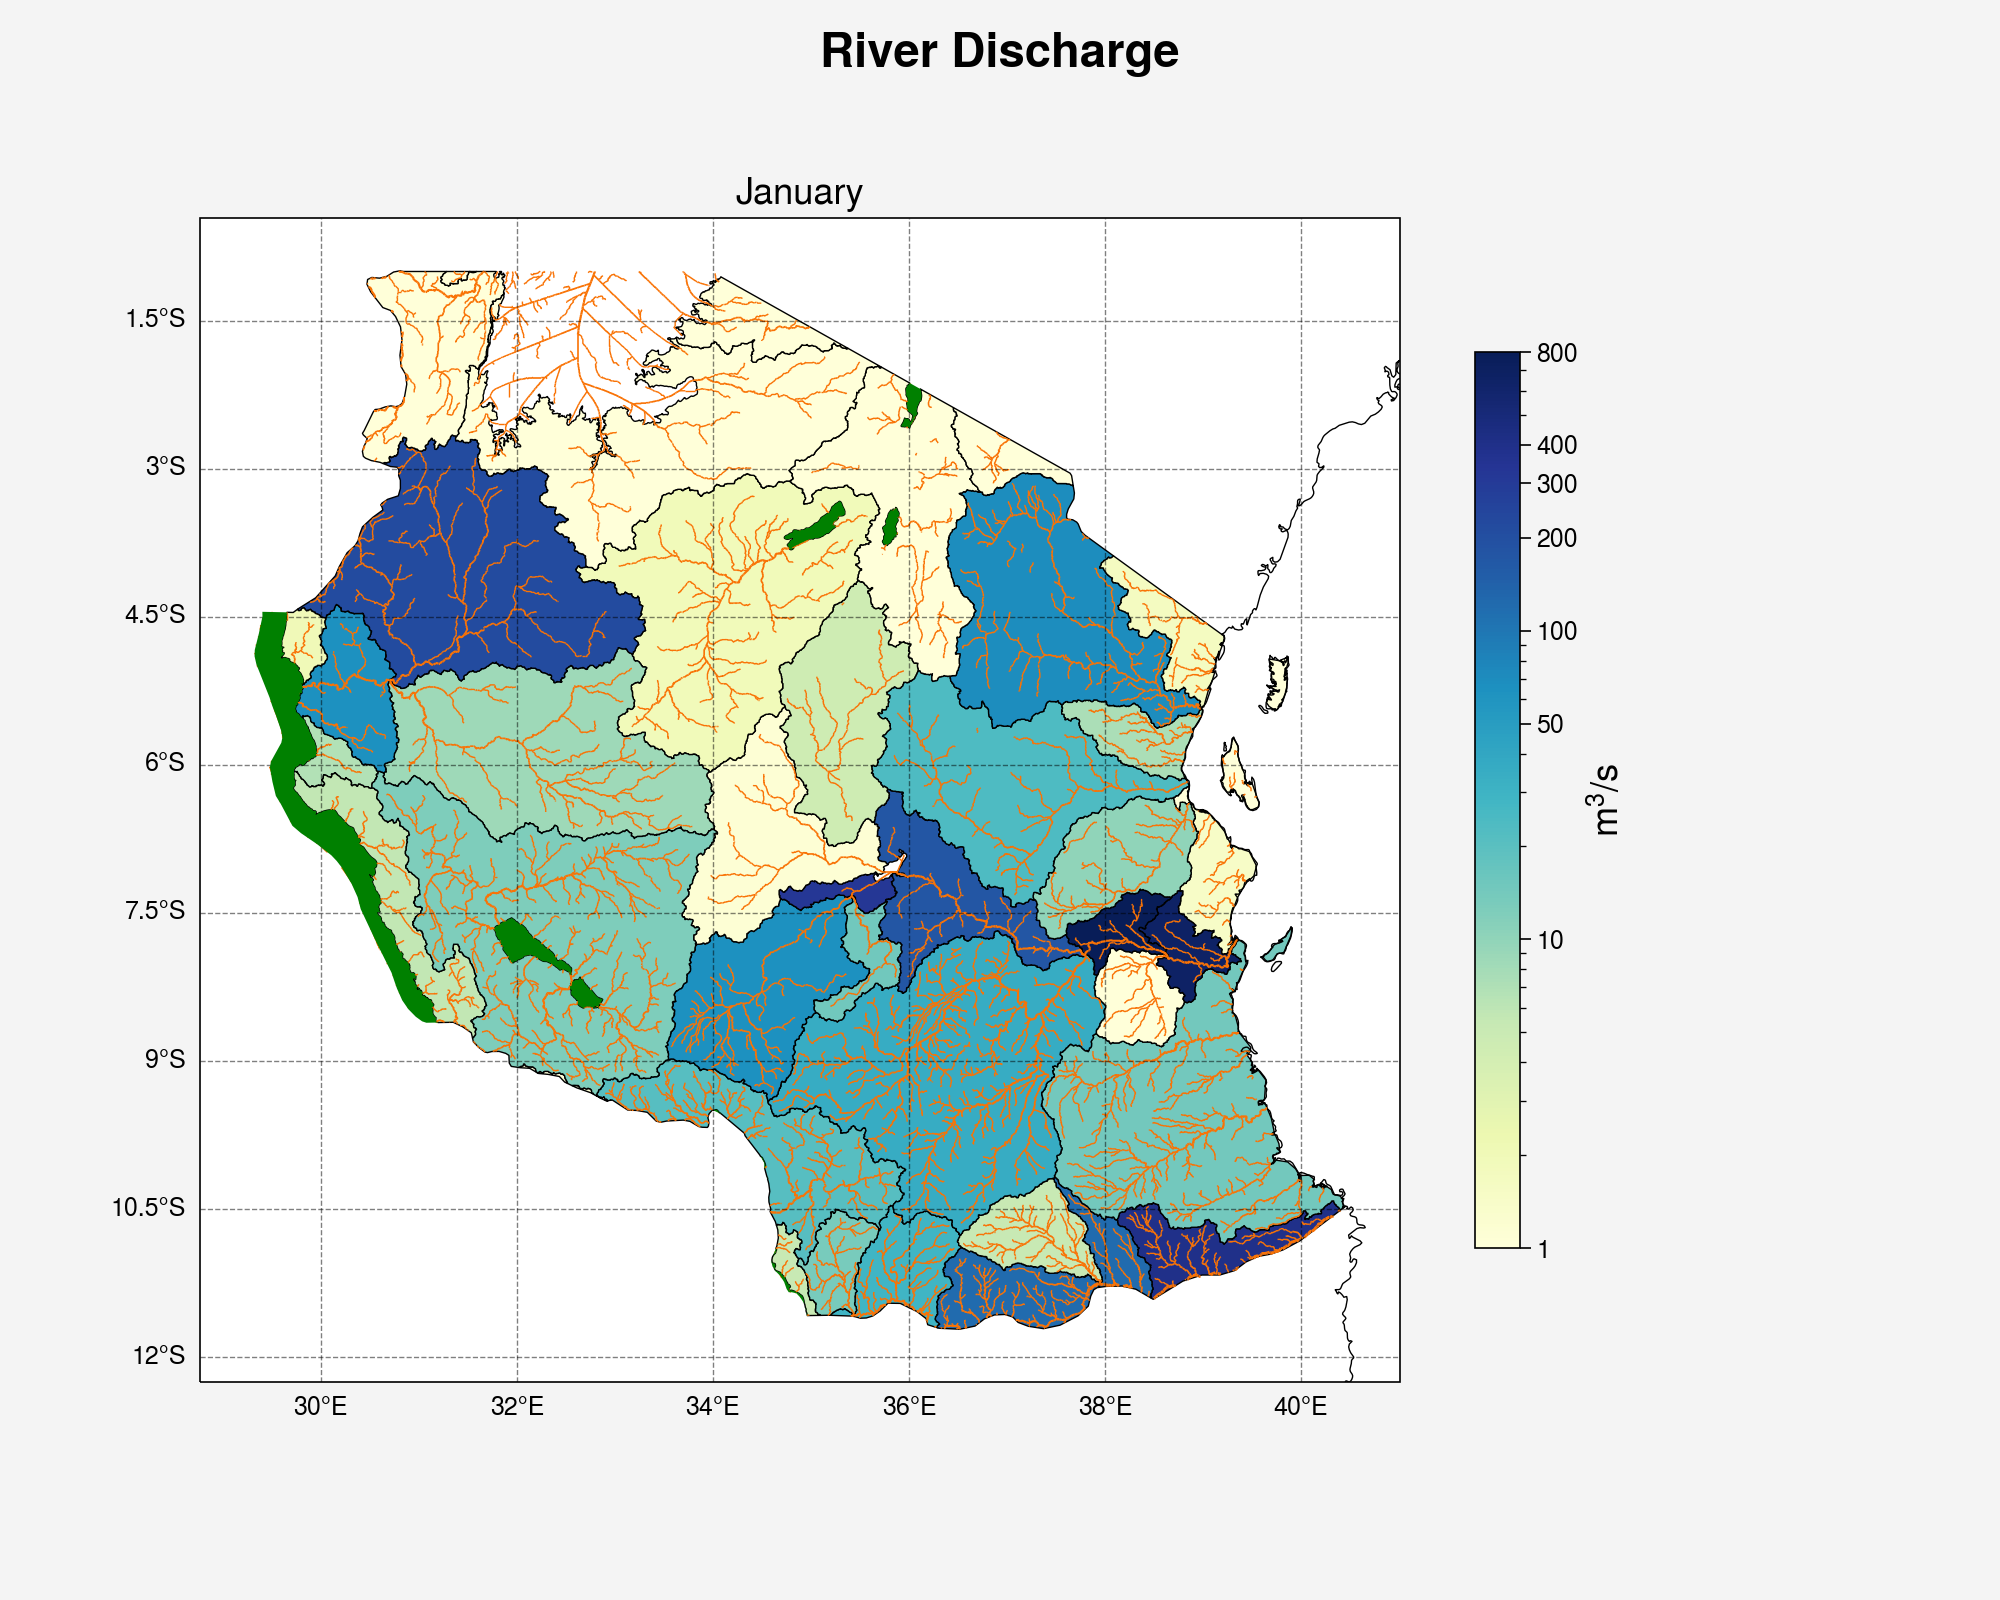

In [11]:
import matplotlib.colors as colors
norm=colors.LogNorm(vmin=1, vmax=800)
ticks = [1,10,50,100,200,300,400,800]
units = r'$m^{3}/s$'
gdf[f'mean_river_discharge'] = gdf[f'mean_river_discharge'].fillna(1)

fig = plotting(gdf, country_rivers, country_lakes_l5, units, ticks, norm)
plt.savefig(f'{output_path}DOWNSCALED_rd_{country}_l5_hydro_glofas_v4_m{month}.png')

### L12 Basins

In [7]:
shp_basins_l12 = gpd.read_file('../hydrobasins/hybas_lake_af_lev12_v1c.shp')   
lakes_l12 = shp_basins_l12[shp_basins_l12.LAKE == 1].geometry # Saving lakes as mask for plotting
country_lakes_l12 = gpd.clip(lakes_l12, geometries_country.geometry)

shp_basins_l12 = shp_basins_l12[shp_basins_l12.LAKE == 0]
country_l12_basins = gpd.clip(shp_basins_l12, geometries_country.geometry)

In the cell below, we add to the L12 dataset a column with the code of the L5 basin in which each L12 sub-basin is found.
This will make basin-scale plotting easier.
PFAF_ID is Pfafstetter ID, which is a convention for splitting watersheds: see the HYDROBASINS manual for more details. Here we take the first 5 digits of the PFAF_ID of the L12 basins because we want to extract basins that are within corresponding L5 basins.

In [9]:
country_l12_basins['L5basin'] = [int(str(i)[:5]) for i in country_l12_basins.PFAF_ID] 

In [7]:
#Annual file for annual plot
#files_list =[]
#for month in range(1,13):
#    df = pd.read_csv(in_path + f'river_discharge_l12_{country}_m{month}.csv').rename(columns={'mean_river_discharge':f'river_discharge_m{month}'})
#    if 'Unnamed: 0' in df.columns:
#        df = df.drop(columns='Unnamed: 0')
#    df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
#    file = gpd.GeoDataFrame(df, geometry='geometry', crs='EPSG:4326')
#    files_list.append(file)
    
#gdf = files_list[0].copy().drop(columns=f'river_discharge_m1')
#monthly_discharge_series = [files_list[i][f'river_discharge_m{i+1}'] for i in range(12)]
#gdf['mean_river_discharge'] = pd.concat(monthly_discharge_series, axis=1).mean(axis=1)

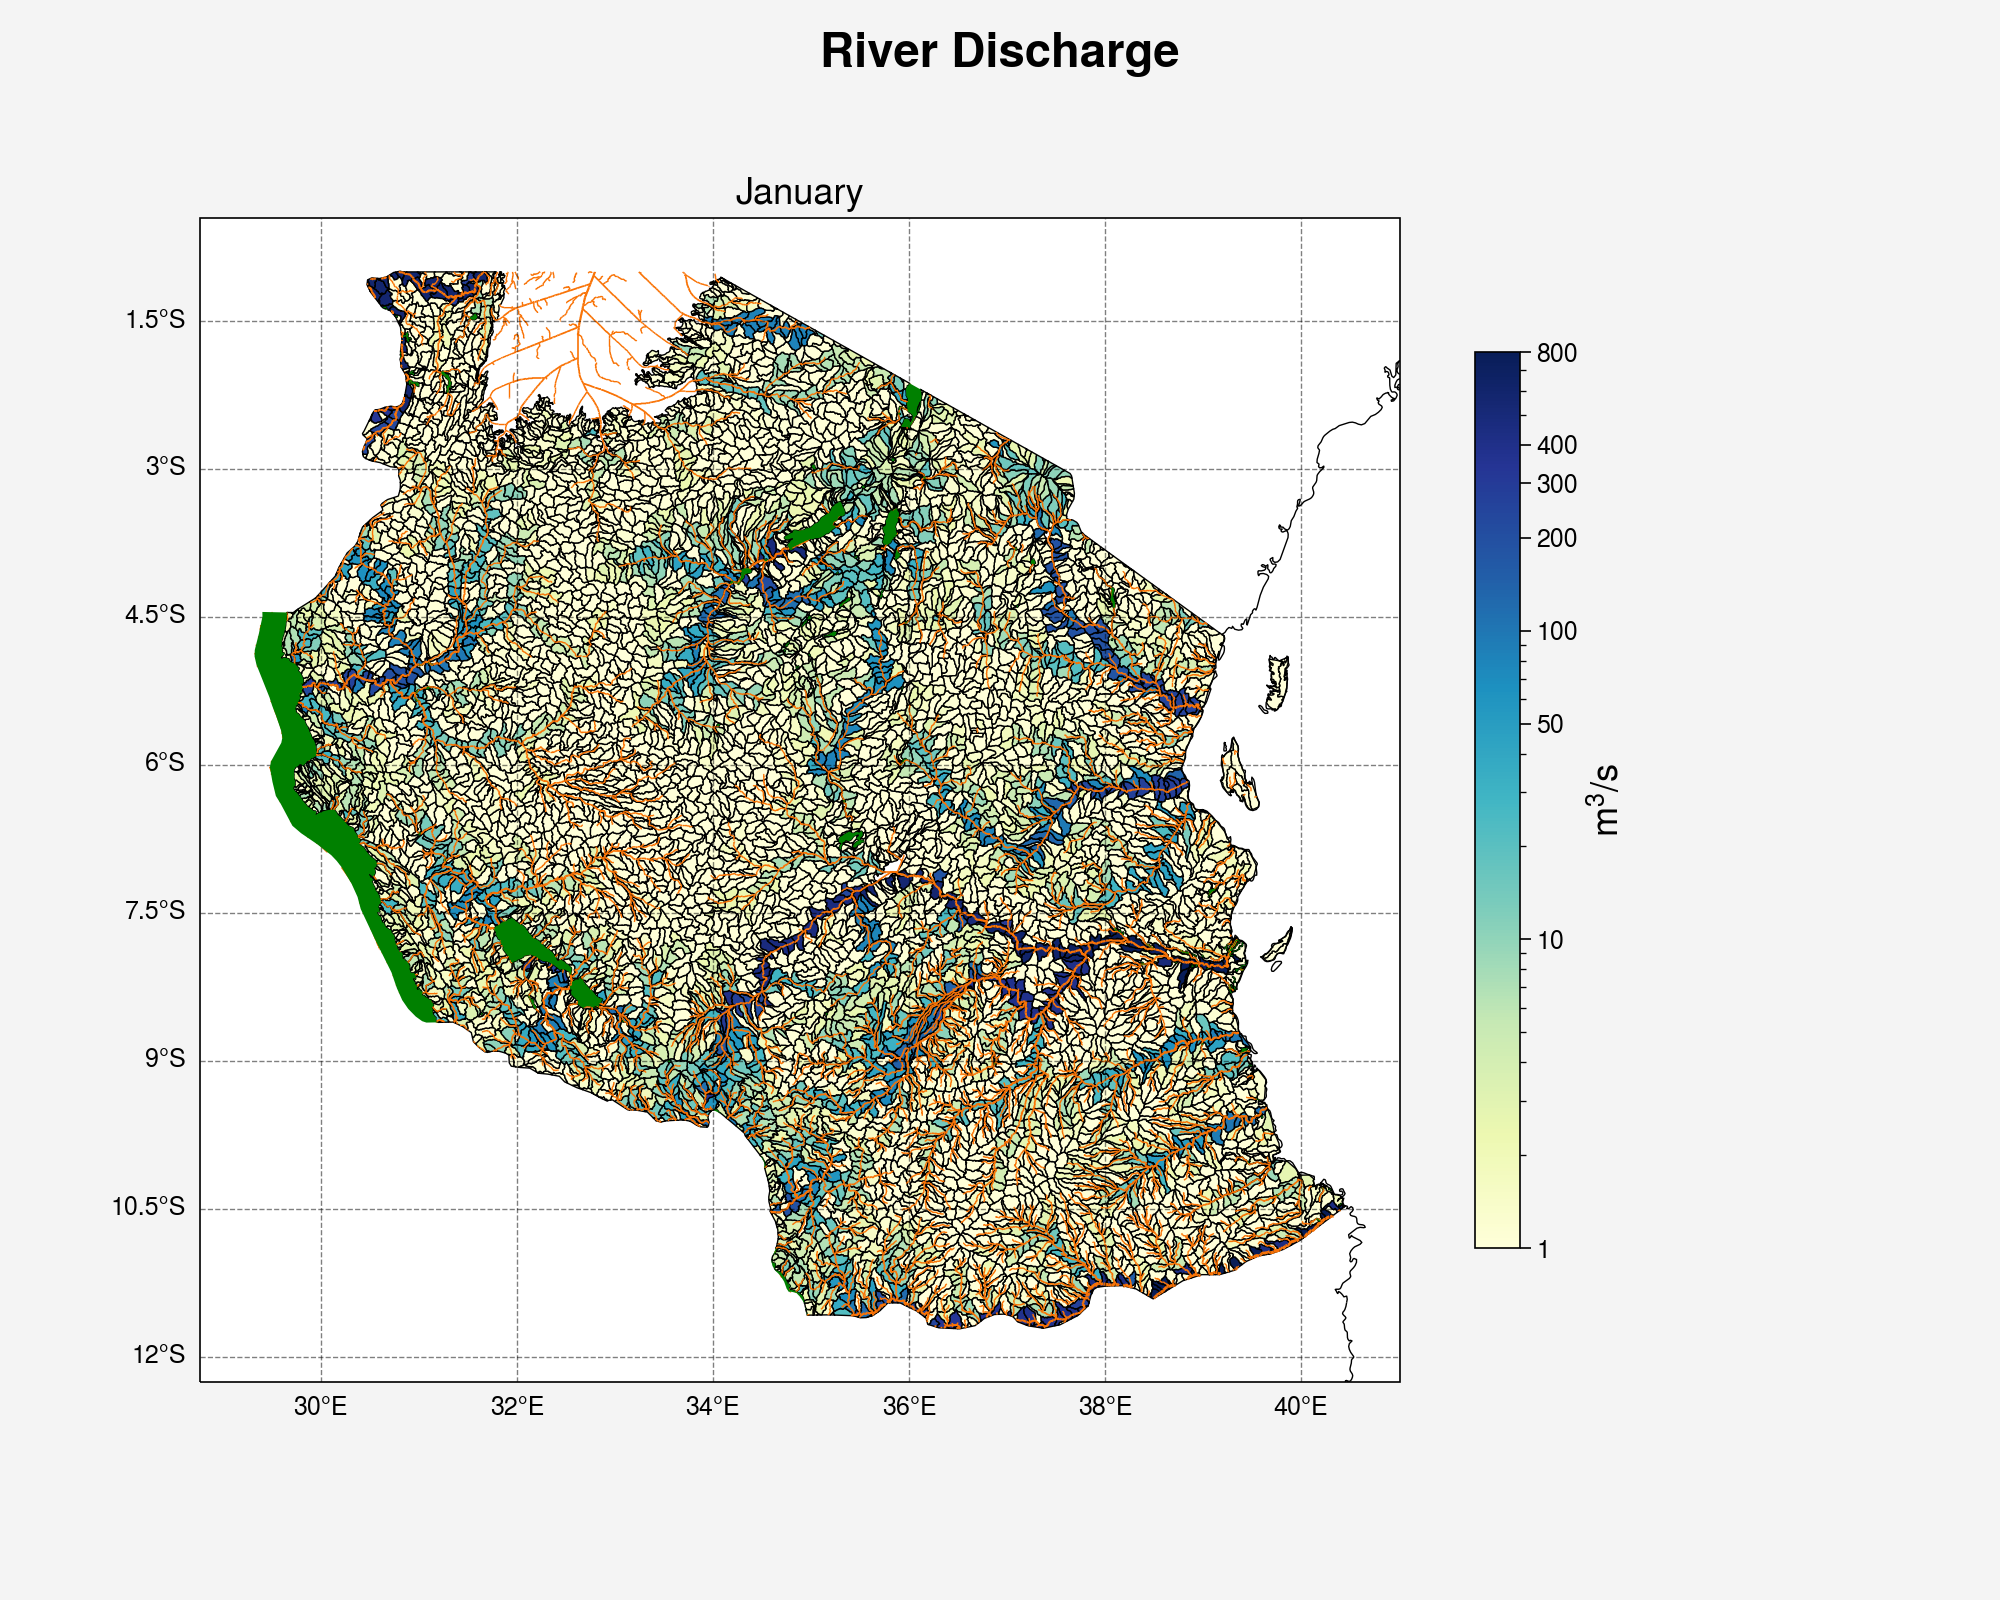

In [11]:
norm=colors.LogNorm(vmin=1, vmax=800)
ticks = [1,10,50,100,200,300,400,800]
units = r'$m^{3}/s$'
gdf[f'mean_river_discharge'] = gdf[f'mean_river_discharge'].fillna(1)

fig = plotting(gdf, country_rivers, country_lakes_l12, units, ticks, norm)
#plt.savefig(f'{output_path}DOWNSCALED_rd_{country}_l12_hydro_glofas_v4_m{month}.png')

#### Subbasin plot: we need to upload also the L5 geometry

In [11]:
### Selecting a basin
sel_basin = gpd.GeoDataFrame(country_l5_basins.iloc[[10]])

In [12]:
selected_basins_l12 = country_l12_basins.loc[country_l12_basins.L5basin.values == sel_basin.PFAF_ID.values]

In [16]:
sel_basin_rivers = gpd.clip(country_rivers, sel_basin)

In [32]:
gdf_sel_basin = gdf.loc[gdf.L5basin.values == sel_basin.PFAF_ID.values]
gdf_sel_basin[f'mean_river_discharge'] = gdf_sel_basin[f'mean_river_discharge'].fillna(1)

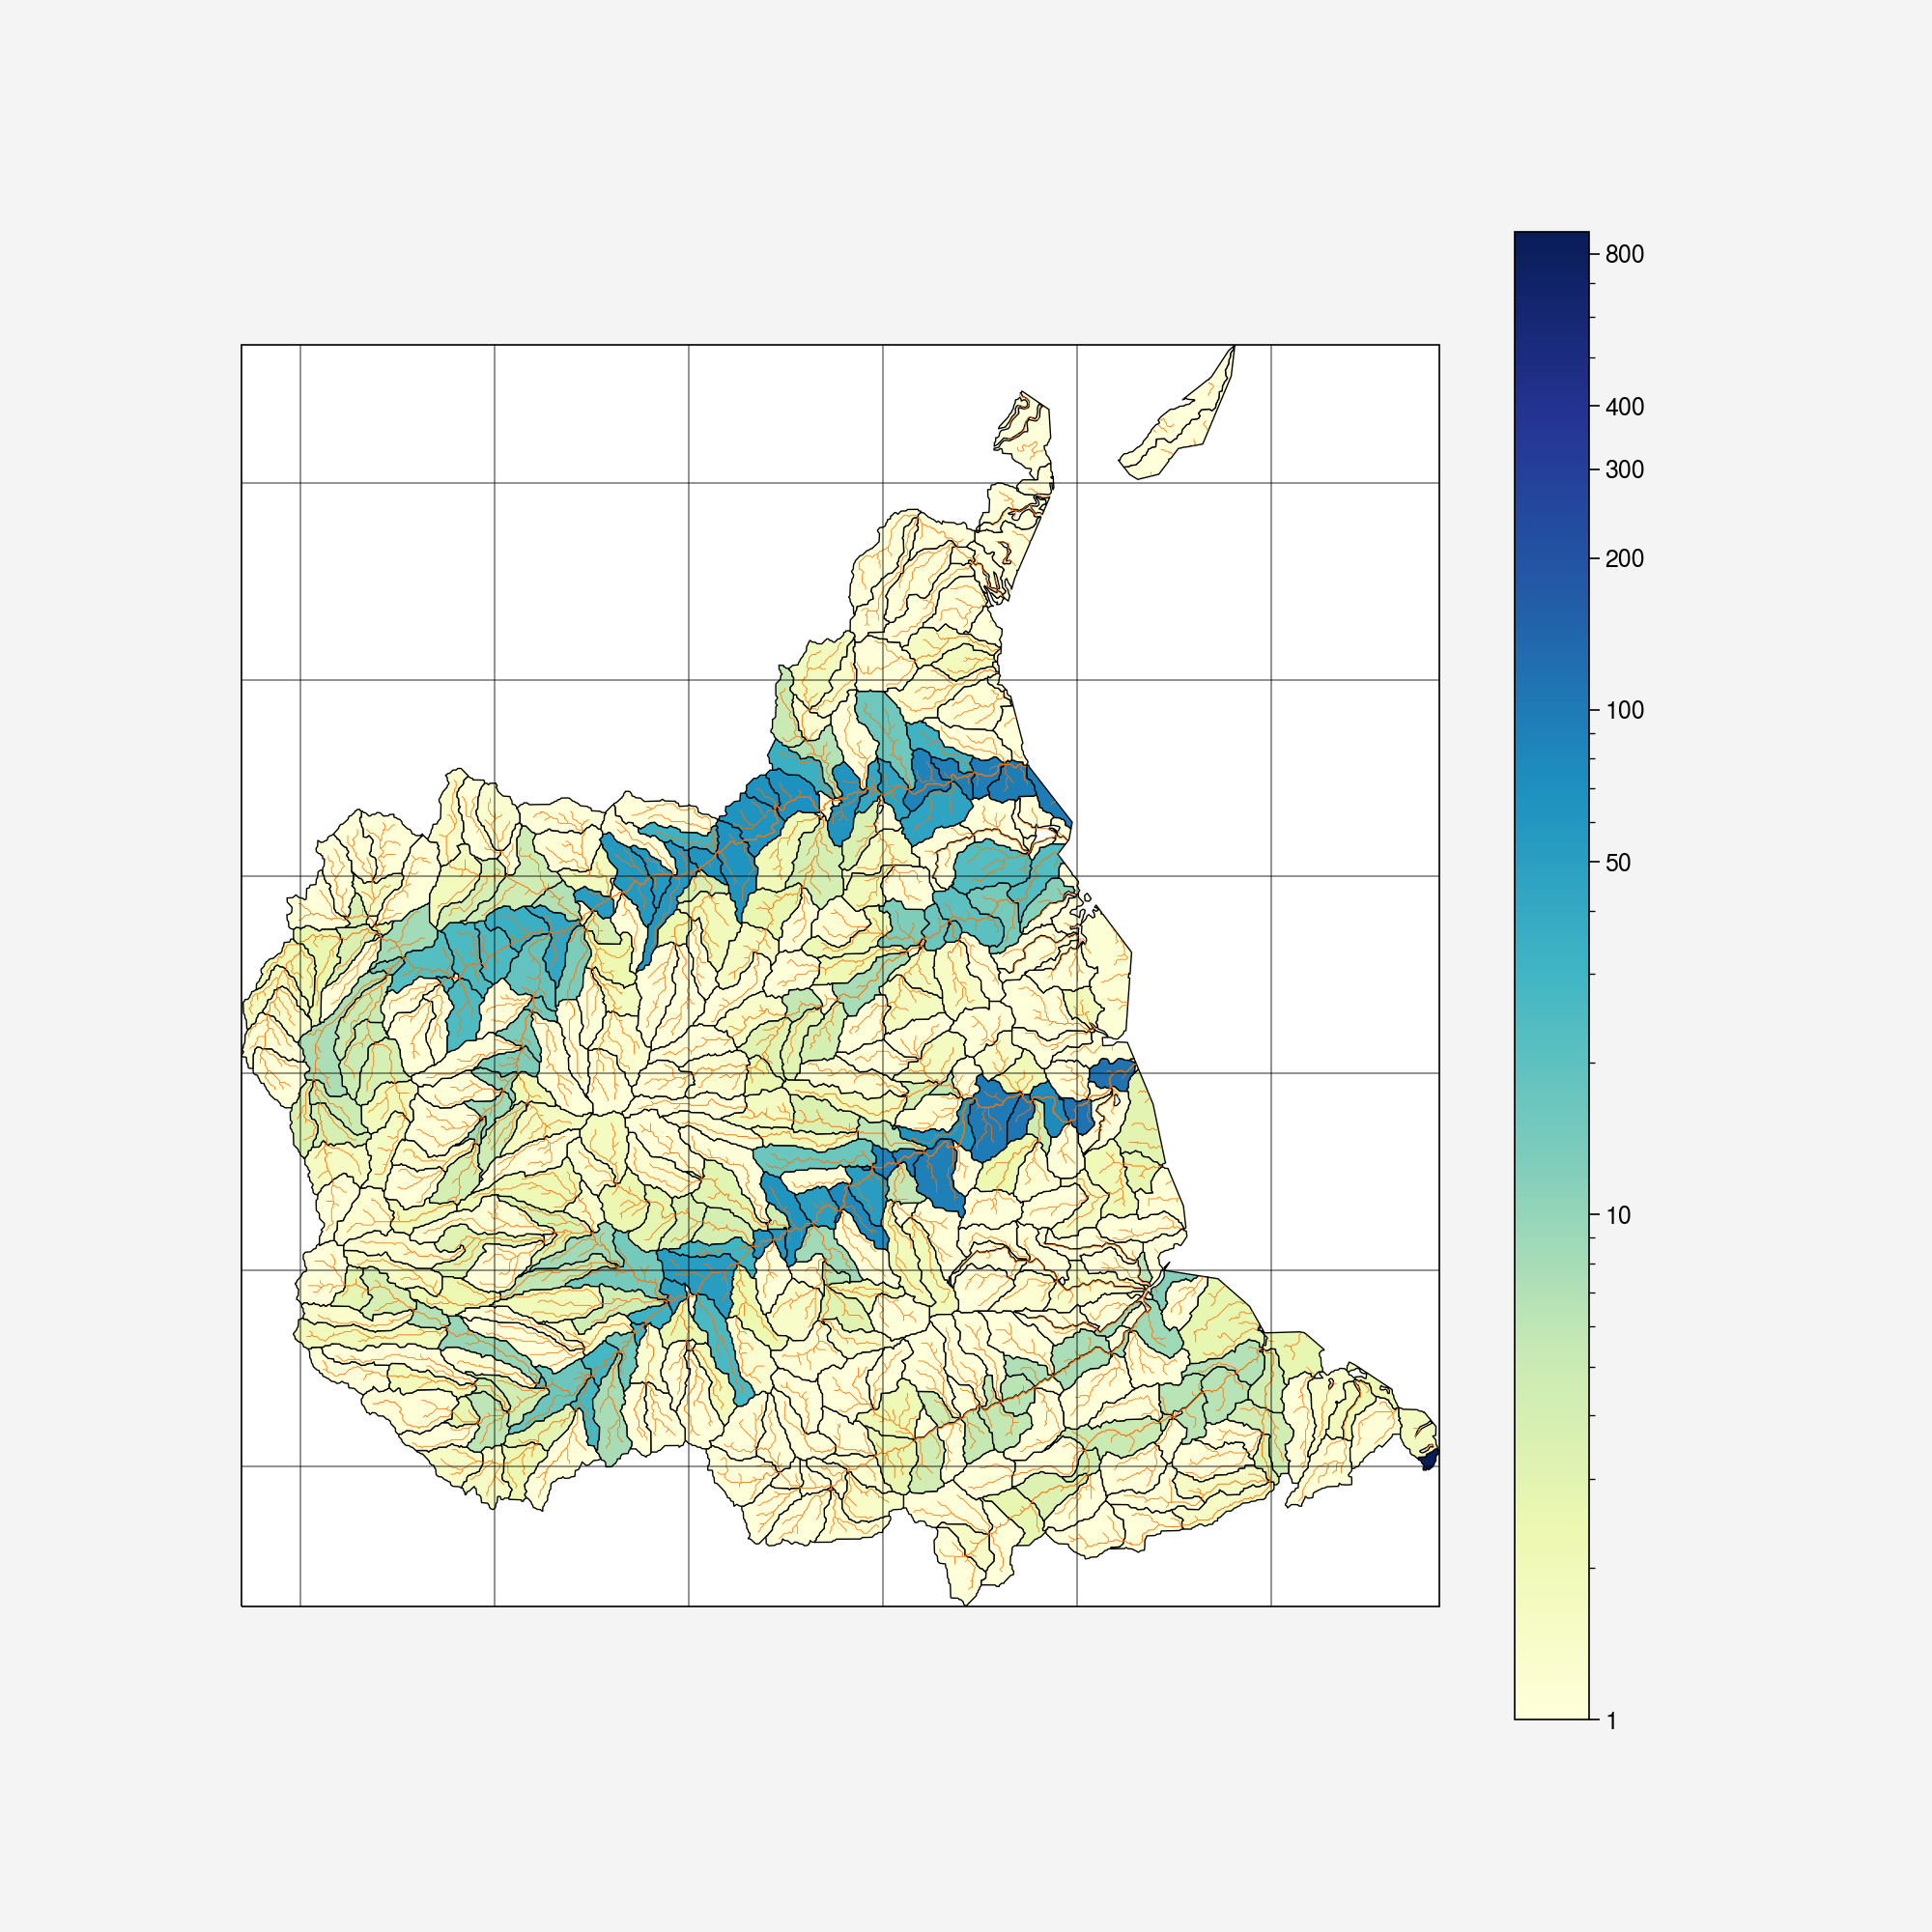

In [33]:
norm=colors.LogNorm(vmin=1, vmax=gdf_sel_basin.mean_river_discharge.max())
basin_bounds = sel_basin.bounds.values[0]

fig, ax = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([basin_bounds[0], basin_bounds[2], basin_bounds[1], basin_bounds[3]])
sel_basin_rivers.plot(ax = ax, color = 'orange', linewidth= 2/sel_basin_rivers['ORD_FLOW'])
#malawi_lakes_l5.plot(ax = ax, facecolor = 'grey')
gl = ax.gridlines(crs=ccrs.PlateCarree(), alpha = 0.5)

gdf_sel_basin.plot(column='mean_river_discharge', ax=ax, cmap='YlGnBu', legend = False, norm = norm, edgecolor = 'k', linewidth = .5)

cbar=plt.cm.ScalarMappable(norm=norm, cmap='YlGnBu')
axCbar=fig.colorbar(cbar, ax=ax)

ticks = [1,10,50,100,200,300,400,800]
ticks[0] = 1
axCbar.set_ticks(ticks)
axCbar.set_ticklabels(ticks)

#plt.savefig(f'{output_path}DOWNSCALED_rd_{country}_l12_hydro_glofas_v4_m{month}_subbasin.png')